In [1]:
from pathlib import Path

import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# Project paths
# ---------------------------------------------------------

project_dir = Path(
    r"C:\Users\Alhaylam Alajmi\Desktop\MUSA 5500\Final Project"
)

priority_path = (
    project_dir
    / "outputs"
    / "Riyadh_500m_Clustering_and_Greening_Priority.gpkg"
)

# ---------------------------------------------------------
# Load final clustering + priority dataset
# ---------------------------------------------------------

ai_priority = gpd.read_file(priority_path)

print("Dataset loaded successfully.")
print("Number of grid cells:", len(ai_priority))
print()
print("Columns:")
print(ai_priority.columns.tolist())

Dataset loaded successfully.
Number of grid cells: 4700

Columns:
['grid_id', 'building_count', 'building_area_m2', 'grid_area_m2', 'building_coverage_pct', 'population', 'mean_ndvi', 'mean_lst_c', 'cluster', 'cluster_name', 'heat_score', 'low_vegetation_score', 'population_score', 'building_score', 'priority_score', 'priority_level', 'geometry']


In [2]:
# ---------------------------------------------------------
# Compare K-Means clusters with greening priority levels
# ---------------------------------------------------------

cluster_priority_table = pd.crosstab(
    ai_priority["cluster_name"],
    ai_priority["priority_level"],
    normalize="index"
) * 100

priority_order = [
    "Very Low",
    "Low",
    "Moderate",
    "High",
    "Very High"
]

cluster_priority_table = cluster_priority_table[
    priority_order
].round(1)

print(
    "Percentage distribution of greening priority levels "
    "within each urban cluster:"
)

display(cluster_priority_table)

Percentage distribution of greening priority levels within each urban cluster:


priority_level,Very Low,Low,Moderate,High,Very High
cluster_name,,,,,
Cooler Lower-Density,68.7,30.7,0.6,0.0,0.0
Dense Populated Urban,0.0,5.0,25.2,33.4,36.5
Greener Cooler Areas,67.6,31.9,0.5,0.0,0.0
Hot Dense Built-Up,0.0,2.4,24.9,39.6,33.0
Hot Low-Density Peripheral,23.3,47.1,25.6,3.7,0.3


In [3]:
# ---------------------------------------------------------
# Summarize High + Very High priority share by AI cluster
# ---------------------------------------------------------

high_priority_share = (
    cluster_priority_table["High"]
    + cluster_priority_table["Very High"]
).sort_values(ascending=False)

high_priority_share = high_priority_share.round(1)

print("Share of High + Very High priority cells within each urban cluster:")
display(high_priority_share.to_frame(name="High + Very High Priority (%)"))

Share of High + Very High priority cells within each urban cluster:


,High + Very High Priority (%)
cluster_name,
Hot Dense Built-Up,72.6
Dense Populated Urban,69.9
Hot Low-Density Peripheral,4.0
Cooler Lower-Density,0.0
Greener Cooler Areas,0.0


In [4]:
# ---------------------------------------------------------
# Add AI-assisted priority association to each grid cell
# ---------------------------------------------------------

cluster_priority_association = (
    high_priority_share
    .to_dict()
)

ai_priority["ai_priority_association_pct"] = (
    ai_priority["cluster_name"]
    .map(cluster_priority_association)
)

print("AI-assisted priority association added successfully.")
print()

display(
    ai_priority[
        [
            "grid_id",
            "cluster_name",
            "priority_level",
            "ai_priority_association_pct"
        ]
    ].head(10)
)

AI-assisted priority association added successfully.



,grid_id,cluster_name,priority_level,ai_priority_association_pct
0,1,Cooler Lower-Density,Very Low,0.0
1,2,Cooler Lower-Density,Very Low,0.0
2,3,Hot Low-Density Peripheral,Very Low,4.0
3,4,Dense Populated Urban,Moderate,69.9
4,5,Dense Populated Urban,Moderate,69.9
5,6,Cooler Lower-Density,Low,0.0
6,7,Cooler Lower-Density,Low,0.0
7,8,Dense Populated Urban,High,69.9
8,9,Cooler Lower-Density,Very Low,0.0
9,10,Cooler Lower-Density,Very Low,0.0


Observed AI-association classes:
No Observed Association: 1,003 cells
Limited Association: 1,085 cells
Strong Association: 2,163 cells
Very Strong Association: 449 cells


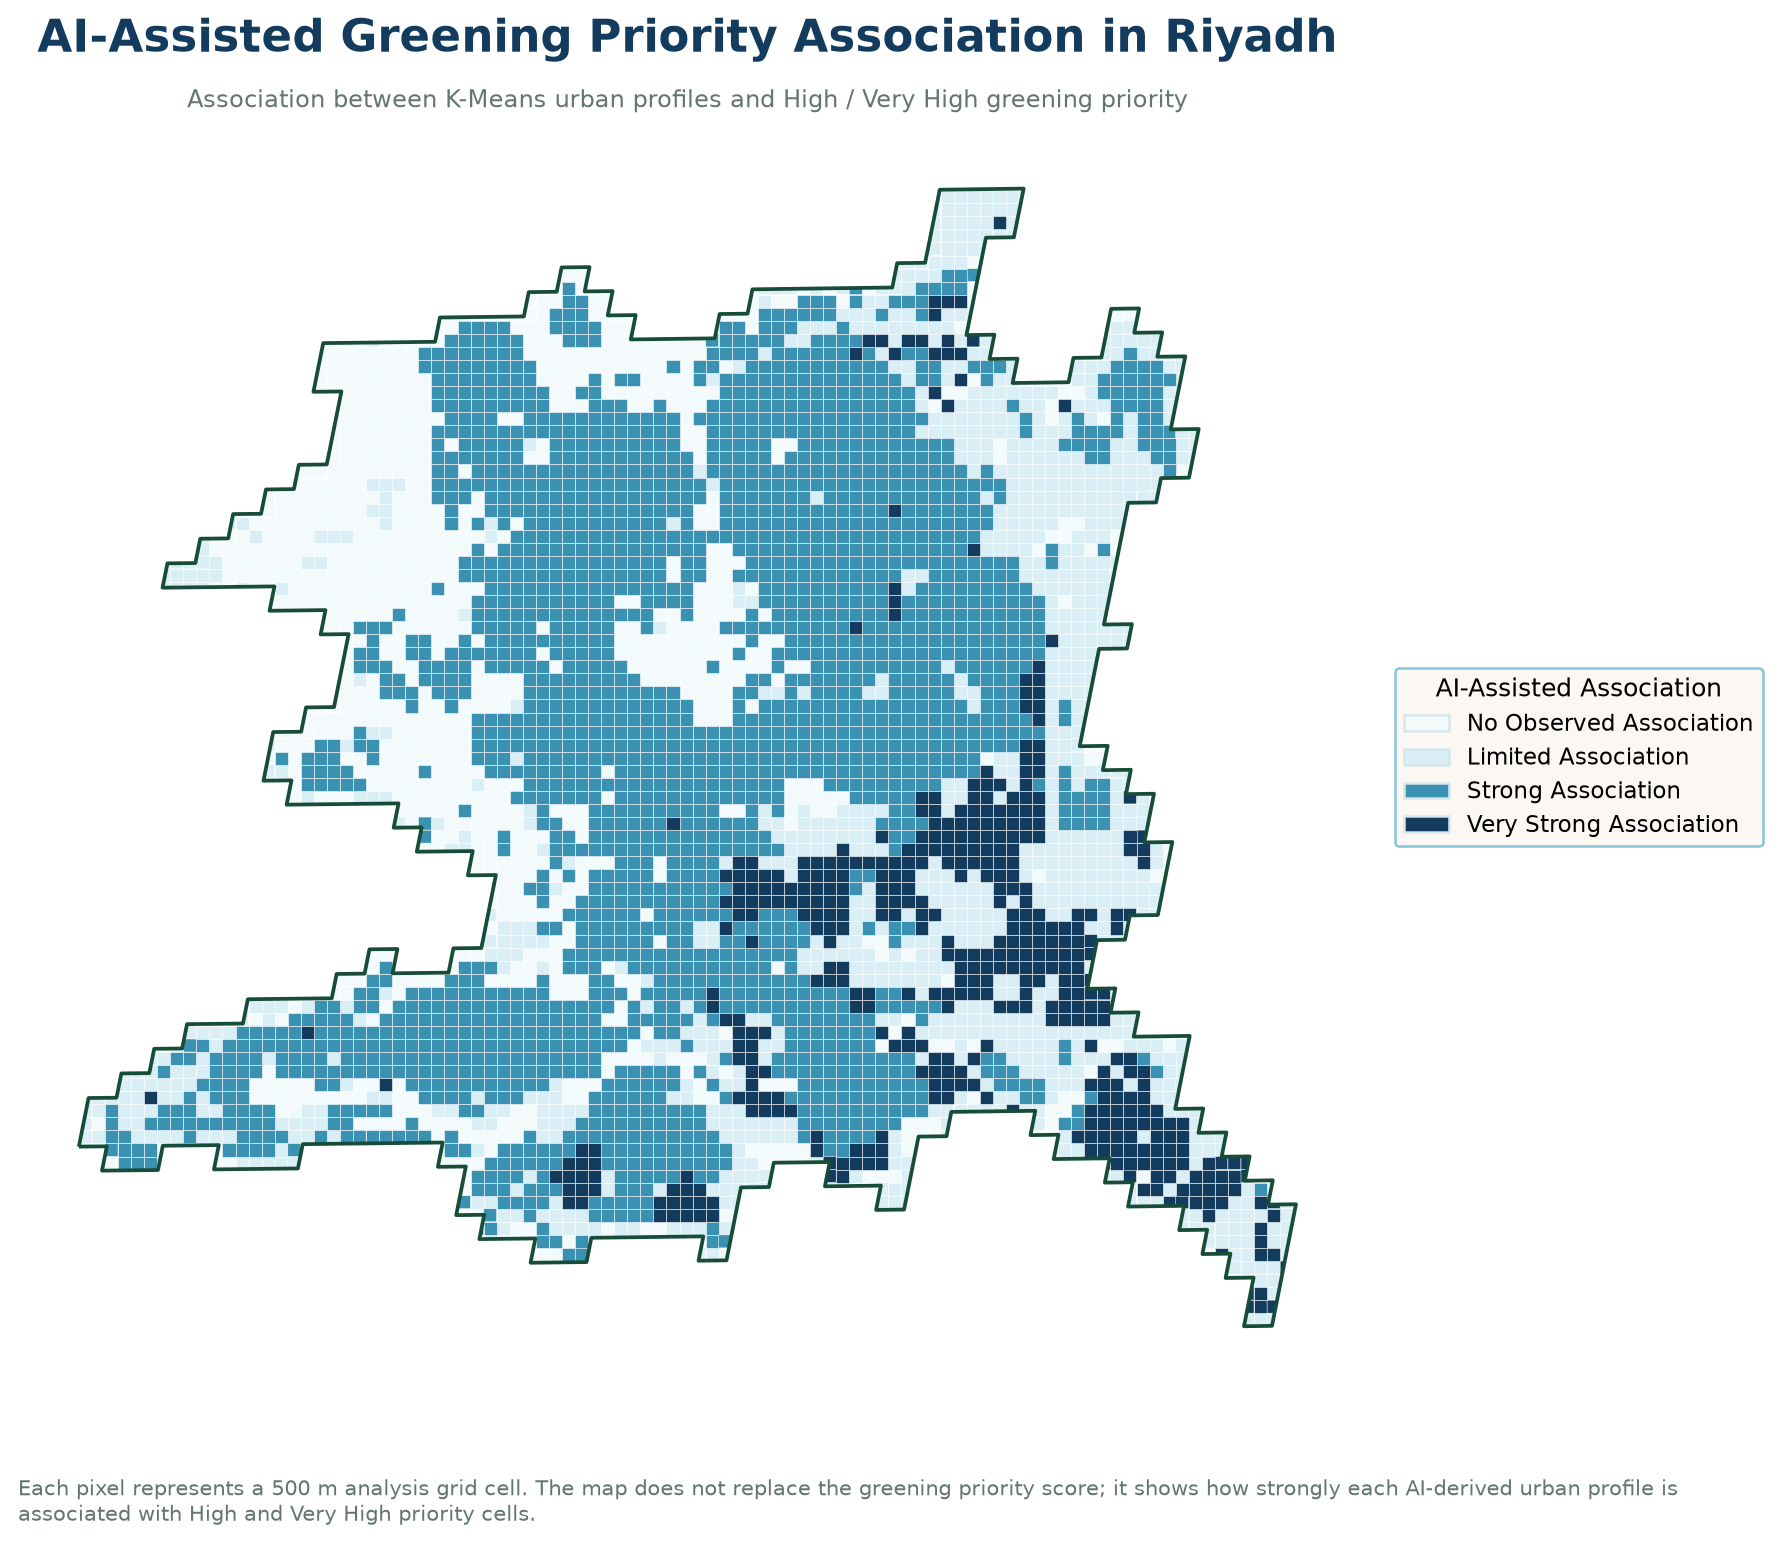

AI-assisted priority association map saved to:
C:\Users\Alhaylam Alajmi\Desktop\MUSA 5500\Final Project\website\assets\images\maps\Riyadh_AI_Assisted_Priority_Association.png


In [6]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import geopandas as gpd

# ---------------------------------------------------------
# Project paths
# ---------------------------------------------------------

project_dir = Path(
    r"C:\Users\Alhaylam Alajmi\Desktop\MUSA 5500\Final Project"
)

boundary_path = (
    project_dir
    / "Data"
    / "boundary"
    / "Riyadh_Urban_Boundary.gpkg"
)

ai_assisted_png_path = (
    project_dir
    / "website"
    / "assets"
    / "images"
    / "maps"
    / "Riyadh_AI_Assisted_Priority_Association.png"
)

ai_assisted_png_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

# ---------------------------------------------------------
# Load Riyadh boundary
# ---------------------------------------------------------

riyadh_boundary = gpd.read_file(boundary_path)
riyadh_boundary_ai = riyadh_boundary.to_crs(ai_priority.crs)

# ---------------------------------------------------------
# AI-assisted association classes
# ---------------------------------------------------------

def association_class(value):
    if value >= 70:
        return "Very Strong Association"
    elif value >= 50:
        return "Strong Association"
    elif value >= 20:
        return "Moderate Association"
    elif value > 0:
        return "Limited Association"
    else:
        return "No Observed Association"

ai_priority["ai_association_class"] = (
    ai_priority["ai_priority_association_pct"]
    .apply(association_class)
)

# ---------------------------------------------------------
# Technology-blue palette
# ---------------------------------------------------------

association_order = [
    "No Observed Association",
    "Limited Association",
    "Moderate Association",
    "Strong Association",
    "Very Strong Association"
]

association_colors = {
    "No Observed Association": "#F3FAFC",
    "Limited Association": "#D9EEF5",
    "Moderate Association": "#8ACBDD",
    "Strong Association": "#3A91B2",
    "Very Strong Association": "#123B5D"
}

# ---------------------------------------------------------
# Identify only classes that actually occur
# ---------------------------------------------------------

observed_classes = [
    level
    for level in association_order
    if level in ai_priority["ai_association_class"].unique()
]

print("Observed AI-association classes:")
for level in observed_classes:
    count = (
        ai_priority["ai_association_class"] == level
    ).sum()

    print(f"{level}: {count:,} cells")

# ---------------------------------------------------------
# Plot
# ---------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 10),
    dpi=180
)

for level in observed_classes:

    subset = ai_priority[
        ai_priority["ai_association_class"] == level
    ]

    subset.plot(
        ax=ax,
        color=association_colors[level],

        # Thin white cell edges make the 500 m grid visible
        edgecolor="#FFFFFF",
        linewidth=0.22
    )

# ---------------------------------------------------------
# Riyadh boundary
# ---------------------------------------------------------

riyadh_boundary_ai.boundary.plot(
    ax=ax,
    color="#174D38",
    linewidth=1.5
)

# ---------------------------------------------------------
# Legend — only categories actually observed
# ---------------------------------------------------------

legend_handles = [
    mpatches.Patch(
        facecolor=association_colors[level],
        edgecolor="#D7E6EB",
        label=level
    )
    for level in observed_classes
]

ax.legend(
    handles=legend_handles,
    title="AI-Assisted Association",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=True,
    facecolor="#FAF7F0",
    edgecolor="#67B7D1",
    fontsize=9,
    title_fontsize=10
)

# ---------------------------------------------------------
# Styling
# ---------------------------------------------------------

ax.set_title(
    "AI-Assisted Greening Priority Association in Riyadh",
    fontsize=18,
    fontweight="bold",
    color="#123B5D",
    pad=32
)

ax.text(
    0.5,
    1.015,
    (
        "Association between K-Means urban profiles and "
        "High / Very High greening priority"
    ),
    transform=ax.transAxes,
    ha="center",
    va="bottom",
    fontsize=9.5,
    color="#65766D"
)

ax.text(
    0.0,
    -0.075,
    (
        "Each pixel represents a 500 m analysis grid cell. "
        "The map does not replace the greening priority score; "
        "it shows how strongly each AI-derived urban profile is "
        "associated with High and Very High priority cells."
    ),
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=8.5,
    color="#65766D",
    wrap=True
)

ax.set_axis_off()

plt.tight_layout()

# ---------------------------------------------------------
# Save PNG
# ---------------------------------------------------------

plt.savefig(
    ai_assisted_png_path,
    dpi=180,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("AI-assisted priority association map saved to:")
print(ai_assisted_png_path)

In [7]:
from pathlib import Path

import geopandas as gpd
import folium

from folium import MacroElement
from jinja2 import Template

# ---------------------------------------------------------
# Project paths
# ---------------------------------------------------------

project_dir = Path(
    r"C:\Users\Alhaylam Alajmi\Desktop\MUSA 5500\Final Project"
)

ai_assisted_html_path = (
    project_dir
    / "website"
    / "assets"
    / "maps"
    / "Riyadh_AI_Assisted_Priority_Interactive.html"
)

ai_assisted_html_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

boundary_path = (
    project_dir
    / "Data"
    / "boundary"
    / "Riyadh_Urban_Boundary.gpkg"
)

# ---------------------------------------------------------
# Load boundary
# ---------------------------------------------------------

riyadh_boundary = gpd.read_file(boundary_path)
riyadh_boundary = riyadh_boundary.to_crs(epsg=4326)

# ---------------------------------------------------------
# Prepare AI-assisted dataset
# ---------------------------------------------------------

ai_map_grid = ai_priority[
    [
        "grid_id",
        "cluster_name",
        "priority_level",
        "priority_score",
        "ai_priority_association_pct",
        "ai_association_class",
        "geometry"
    ]
].copy()

ai_map_grid = ai_map_grid.to_crs(epsg=4326)

ai_map_grid["grid_id"] = (
    ai_map_grid["grid_id"]
    .astype(str)
)

ai_map_grid["priority_score"] = (
    ai_map_grid["priority_score"]
    .round(3)
)

ai_map_grid["ai_priority_association_pct"] = (
    ai_map_grid["ai_priority_association_pct"]
    .round(1)
)

# ---------------------------------------------------------
# Technology-blue palette
# ---------------------------------------------------------

association_colors = {
    "No Observed Association": "#F3FAFC",
    "Limited Association": "#D9EEF5",
    "Moderate Association": "#8ACBDD",
    "Strong Association": "#3A91B2",
    "Very Strong Association": "#123B5D"
}

# ---------------------------------------------------------
# Create map
# ---------------------------------------------------------

center = riyadh_boundary.geometry.union_all().centroid

ai_assisted_map = folium.Map(
    location=[center.y, center.x],
    zoom_start=10,
    tiles="OpenStreetMap",
    control_scale=True
)

# ---------------------------------------------------------
# Riyadh boundary first
# ---------------------------------------------------------

folium.GeoJson(
    data=riyadh_boundary,
    name="Riyadh Urban Boundary",
    style_function=lambda feature: {
        "color": "#174D38",
        "weight": 2.5,
        "fillOpacity": 0
    }
).add_to(ai_assisted_map)

# ---------------------------------------------------------
# AI-assisted association grid
# ---------------------------------------------------------

ai_layer = folium.GeoJson(
    data=ai_map_grid,
    name="AI-Assisted Priority Association",
    style_function=lambda feature: {
        "fillColor": association_colors[
            feature["properties"]["ai_association_class"]
        ],
        "color": "#FFFFFF",
        "weight": 0.35,
        "fillOpacity": 0.90
    },
    highlight_function=lambda feature: {
        "fillColor": association_colors[
            feature["properties"]["ai_association_class"]
        ],
        "color": "#123B5D",
        "weight": 1.8,
        "fillOpacity": 1.0
    }
).add_to(ai_assisted_map)

# ---------------------------------------------------------
# Custom styled popup
# ---------------------------------------------------------

class AIAssistedStyledPopup(MacroElement):

    def __init__(self, geojson_layer):
        super().__init__()

        self._name = "AIAssistedStyledPopup"
        self.geojson_name = geojson_layer.get_name()

        self._template = Template("""
        {% macro script(this, kwargs) %}

        {{ this.geojson_name }}.eachLayer(function(layer) {

            layer.on("click", function(e) {

                const p = layer.feature.properties;

                const html = `
                    <div style="
                        font-family: Arial, sans-serif;
                        min-width: 265px;
                        background: #FAF7F0;
                        border: 1px solid #67B7D1;
                        border-radius: 12px;
                        padding: 14px 16px;
                        color: #2B2B2B;
                        box-shadow: 0 8px 20px rgba(18, 59, 93, 0.18);
                    ">

                        <div style="
                            font-size: 16px;
                            font-weight: 700;
                            color: #123B5D;
                            margin-bottom: 10px;
                            padding-bottom: 7px;
                            border-bottom: 2px solid #67B7D1;
                        ">
                            AI-Assisted Priority Profile
                        </div>

                        <div style="
                            line-height: 1.65;
                            font-size: 13px;
                        ">

                            <div>
                                <span style="
                                    font-weight: 600;
                                    color: #1F6F8B;
                                ">
                                    Urban Cluster Profile
                                </span><br>
                                ${p.cluster_name}
                            </div>

                            <div style="margin-top:8px;">
                                <span style="
                                    font-weight: 600;
                                    color: #1F6F8B;
                                ">
                                    AI-Assisted Association
                                </span><br>
                                ${p.ai_association_class}
                            </div>

                            <div style="margin-top:8px;">
                                <span style="
                                    font-weight: 600;
                                    color: #1F6F8B;
                                ">
                                    High + Very High Priority Share
                                </span><br>
                                ${Number(p.ai_priority_association_pct).toFixed(1)}%
                            </div>

                            <div style="margin-top:8px;">
                                <span style="
                                    font-weight: 600;
                                    color: #1F6F8B;
                                ">
                                    Current Priority Level
                                </span><br>
                                ${p.priority_level}
                            </div>

                            <div style="margin-top:8px;">
                                <span style="
                                    font-weight: 600;
                                    color: #1F6F8B;
                                ">
                                    Priority Score
                                </span><br>
                                ${Number(p.priority_score).toFixed(3)}
                            </div>

                        </div>

                    </div>
                `;

                L.popup({
                    maxWidth: 360,
                    className: "ai-assisted-custom-popup"
                })
                .setLatLng(e.latlng)
                .setContent(html)
                .openOn({{ this._parent.get_name() }});

            });

        });

        {% endmacro %}
        """)

AIAssistedStyledPopup(
    ai_layer
).add_to(ai_assisted_map)

# ---------------------------------------------------------
# Legend
# ---------------------------------------------------------

observed_classes = [
    level
    for level in [
        "No Observed Association",
        "Limited Association",
        "Moderate Association",
        "Strong Association",
        "Very Strong Association"
    ]
    if level in ai_map_grid["ai_association_class"].unique()
]

legend_rows = ""

for level in observed_classes:
    color = association_colors[level]

    legend_rows += f"""
    <div style="margin-top:4px;">
        <span style="
            display:inline-block;
            width:14px;
            height:14px;
            background:{color};
            margin-right:7px;
            border:1px solid #D7E6EB;
        "></span>
        {level}
    </div>
    """

legend_html = f"""
<div style="
    position: fixed;
    bottom: 35px;
    left: 35px;
    z-index: 9999;
    background: #FAF7F0;
    border: 1px solid #67B7D1;
    border-radius: 10px;
    padding: 12px 14px;
    font-family: Arial, sans-serif;
    font-size: 12px;
    color: #2B2B2B;
    box-shadow: 0 6px 16px rgba(18,59,93,0.15);
">

    <div style="
        font-weight: 700;
        color: #123B5D;
        margin-bottom: 8px;
    ">
        AI-Assisted Association
    </div>

    {legend_rows}

</div>
"""

ai_assisted_map.get_root().html.add_child(
    folium.Element(legend_html)
)

# ---------------------------------------------------------
# Layer control
# ---------------------------------------------------------

folium.LayerControl(
    collapsed=False
).add_to(ai_assisted_map)

# ---------------------------------------------------------
# Fit map to Riyadh
# ---------------------------------------------------------

minx, miny, maxx, maxy = riyadh_boundary.total_bounds

ai_assisted_map.fit_bounds([
    [miny, minx],
    [maxy, maxx]
])

# ---------------------------------------------------------
# Save
# ---------------------------------------------------------

ai_assisted_map.save(
    ai_assisted_html_path
)

print("Interactive AI-assisted priority map saved to:")
print(ai_assisted_html_path)

# ---------------------------------------------------------
# Display
# ---------------------------------------------------------

ai_assisted_map

Interactive AI-assisted priority map saved to:
C:\Users\Alhaylam Alajmi\Desktop\MUSA 5500\Final Project\website\assets\maps\Riyadh_AI_Assisted_Priority_Interactive.html
